# Exp1 analysis 7b: prefix-region KV patching (F1 recipient, body stays F1)

In [1]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def latest(sub):
    run = sorted(p for p in Path('../runs').iterdir() if (p / sub / 'results.jsonl').exists())[-1]
    return run, [json.loads(l) for l in (run / sub / 'results.jsonl').read_text().splitlines()]


RUN, ROWS = latest('exp1_patch_prefix')
BRUN, BROWS = latest('exp1_patch')
FIG = Path('../figures/exp1')
DONORS = ('H+', 'H-', 'P1', 'P2', 'F2')
NL, NH = 28, 8


def group(rows):
    g = defaultdict(list)
    for r in rows:
        g[r['donor'], r['config']].append((r['recovery'], r['cont_logprob_delta']))
    return g


G, BG = group(ROWS), group(BROWS)


def stat(d, c, k=0, g=None):
    a = np.array((G if g is None else g)[d, c])[:, k]
    return a.mean(), a.std()


print(RUN.name, len(ROWS), 'rows;', 'body run', BRUN.name, len(BROWS), 'rows')

20261014-111340-0.6B 7805 rows; body run 20261013-233146-0.6B 7785 rows


H+ prefix all_kv +0.93±0.08 lp +32.34  prefix all_k -0.27±1.10 lp -16.58  prefix all_v -1.32±0.51 lp +5.22  body all_kv -1.18±1.00 lp +2.56  full all_kv +1.00±0.00 lp +33.34
H- prefix all_kv +0.92±0.09 lp +41.41  prefix all_k +0.60±0.36 lp -6.94  prefix all_v -1.08±0.91 lp +6.47  body all_kv -0.06±0.47 lp +1.50  full all_kv +1.00±0.00 lp +45.36
P1 prefix all_kv +0.98±0.01 lp +41.67  prefix all_k -0.38±0.25 lp -13.23  prefix all_v +0.53±0.15 lp +4.45  body all_kv -0.10±0.18 lp +2.48  full all_kv +1.00±0.00 lp +42.43
P2 prefix all_kv +0.90±0.10 lp +27.34  prefix all_k -0.57±0.34 lp -14.70  prefix all_v +0.28±0.12 lp +3.65  body all_kv -0.00±0.34 lp +3.20  full all_kv +1.00±0.00 lp +30.10
F2 prefix all_kv +0.64±0.22 lp +2.70  prefix all_k +0.07±0.56 lp -0.43  prefix all_v -0.05±1.00 lp +1.64  body all_kv +0.72±0.15 lp +4.76  full all_kv +1.00±0.00 lp +5.55
reverse +0.68±0.52 lp +17.71


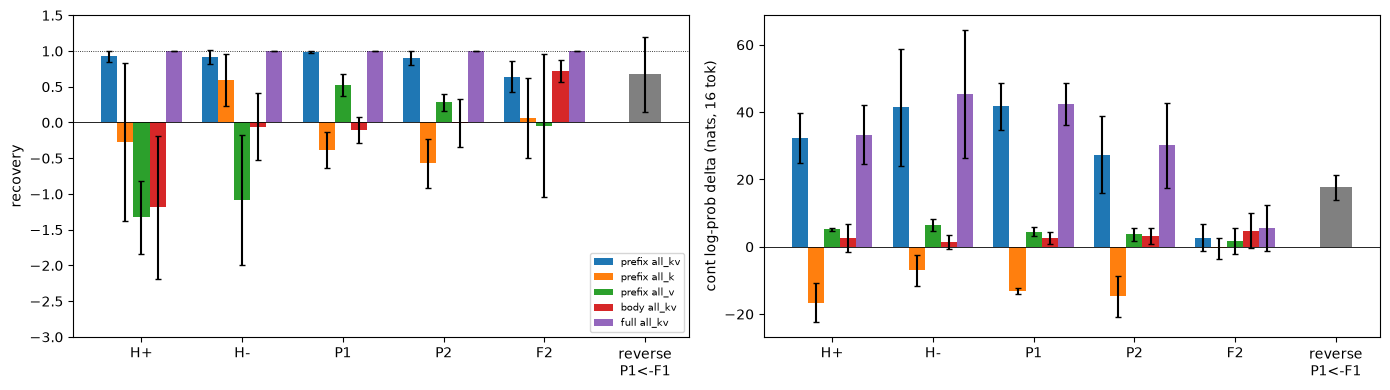

In [2]:
# Region "prefix" = [0, body start): template head + prefix + delimiter; full_all_kv = [0, body end), must be ~1.
BARS = [('prefix all_kv', 'all_kv', None), ('prefix all_k', 'all_k', None), ('prefix all_v', 'all_v', None),
        ('body all_kv', 'all_kv', 'body'), ('full all_kv', 'full_all_kv', None)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, k, lab in zip(axes, (0, 1), ('recovery', 'cont log-prob delta (nats, 16 tok)')):
    w = 0.16
    for j, (name, c, src) in enumerate(BARS):
        m = [stat(d, c, k, BG if src else None) for d in DONORS]
        ax.bar(np.arange(len(DONORS)) + (j - 2) * w, [x[0] for x in m], w, yerr=[x[1] for x in m], capsize=2, label=name)
    mu, sd = stat('F1', 'reverse_all_kv', k)
    ax.bar(len(DONORS), mu, w * 2, yerr=sd, capsize=2, color='gray')
    ax.set_xticks(range(len(DONORS) + 1), [*DONORS, 'reverse\nP1<-F1'])
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylabel(lab)
axes[0].axhline(1, color='k', ls=':', lw=0.6)
axes[0].set_ylim(-3, 1.5)
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / 'patch_prefix_summary.png', dpi=120)
for d in DONORS:
    print(d, '  '.join(f'{n} {stat(d, c, 0, BG if s else None)[0]:+.2f}±{stat(d, c, 0, BG if s else None)[1]:.2f}'
                       f' lp {stat(d, c, 1, BG if s else None)[0]:+.2f}' for n, c, s in BARS))
print('reverse', f'{stat("F1", "reverse_all_kv")[0]:+.2f}±{stat("F1", "reverse_all_kv")[1]:.2f} lp {stat("F1", "reverse_all_kv", 1)[0]:+.2f}')

H+ best single 21 +0.56 | fwd>=0.5 at 15 | bwd>=0.5 from 21
H- best single 21 +0.40 | fwd>=0.5 at 15 | bwd>=0.5 from 9
P1 best single 11 +0.35 | fwd>=0.5 at 14 | bwd>=0.5 from 17
P2 best single 17 +0.21 | fwd>=0.5 at 14 | bwd>=0.5 from 14
F2 best single 24 +0.27 | fwd>=0.5 at 21 | bwd>=0.5 from 19


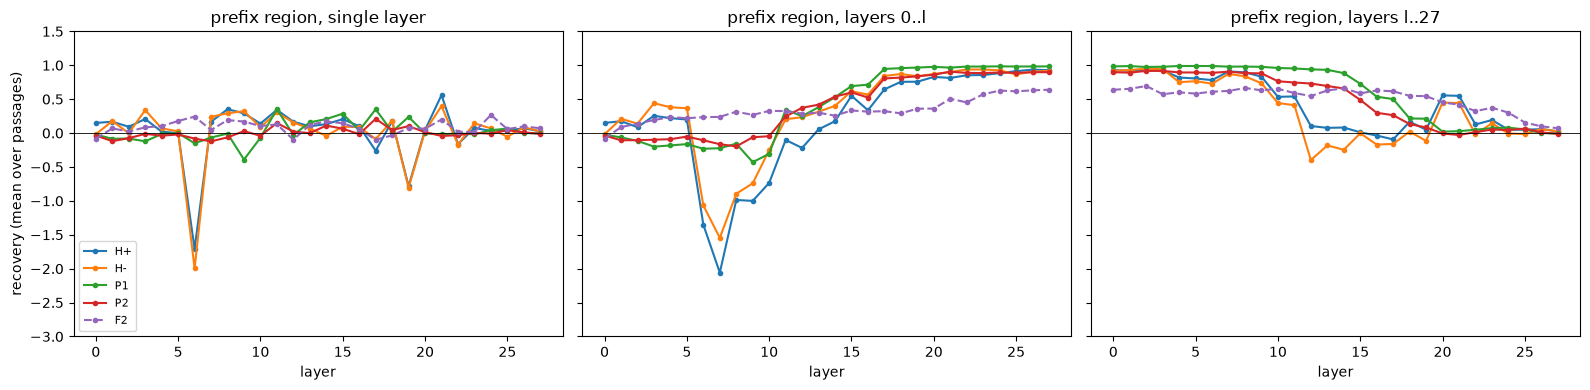

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (pre, title) in zip(axes, [('layer_', 'single layer'), ('cum_fwd_', 'layers 0..l'), ('cum_bwd_', 'layers l..27')]):
    for d in DONORS:
        m = np.array([stat(d, f'{pre}{l}') for l in range(NL)])
        ax.plot(range(NL), m[:, 0], marker='.', label=d, ls='--' if d == 'F2' else '-')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_title(f'prefix region, {title}')
    ax.set_xlabel('layer')
axes[0].set_ylabel('recovery (mean over passages)')
axes[0].set_ylim(-3, 1.5)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'patch_prefix_layers.png', dpi=120)
for d in DONORS:
    single = np.array([stat(d, f'layer_{l}')[0] for l in range(NL)])
    fwd = np.array([stat(d, f'cum_fwd_{l}')[0] for l in range(NL)])
    bwd = np.array([stat(d, f'cum_bwd_{l}')[0] for l in range(NL)])
    print(d, 'best single', single.argmax(), f'{single.max():+.2f}', '| fwd>=0.5 at', int(np.argmax(fwd >= 0.5)) if (fwd >= 0.5).any() else None,
          '| bwd>=0.5 from', int(np.where(bwd >= 0.5)[0].max()) if (bwd >= 0.5).any() else None)

H+ max head (np.int64(21), np.int64(5)) +0.34 min (np.int64(6), np.int64(0)) -1.03
H- max head (np.int64(3), np.int64(0)) +0.34 min (np.int64(6), np.int64(0)) -0.98
P1 max head (np.int64(11), np.int64(3)) +0.27 min (np.int64(9), np.int64(1)) -0.33
P2 max head (np.int64(17), np.int64(6)) +0.12 min (np.int64(17), np.int64(1)) -0.11
F2 max head (np.int64(24), np.int64(5)) +0.28 min (np.int64(0), np.int64(4)) -0.09


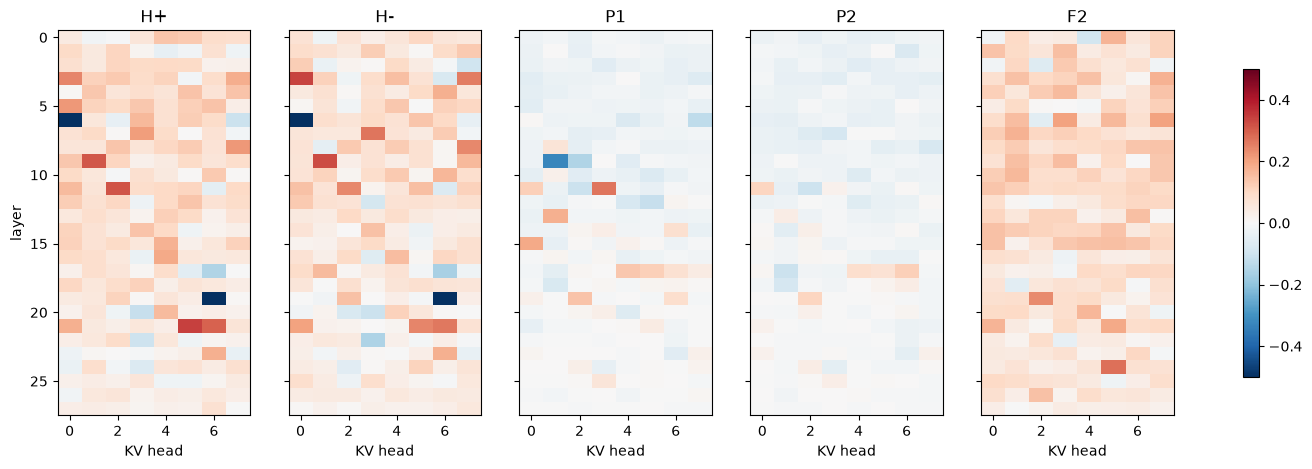

In [4]:
fig, axes = plt.subplots(1, len(DONORS), figsize=(18, 5), sharey=True)
for ax, d in zip(axes, DONORS):
    H = np.array([[stat(d, f'head_{l}_{h}')[0] for h in range(NH)] for l in range(NL)])
    im = ax.imshow(H, aspect='auto', cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    ax.set_title(d)
    ax.set_xlabel('KV head')
    print(d, 'max head', np.unravel_index(H.argmax(), H.shape), f'{H.max():+.2f}', 'min', np.unravel_index(H.argmin(), H.shape), f'{H.min():+.2f}')
axes[0].set_ylabel('layer')
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(FIG / 'patch_prefix_heads.png', dpi=120, bbox_inches='tight')